# **Lab 9 – Morphological Operations (Solution)**

**Name:** Abdullah Hejji Alnuwaysir  
**Student ID:** 2240005501  
**Course:** ARTI403 – Image Processing

**Objective:** Apply erosion, dilation, opening and closing to a new binary image (Balls) and investigate how the structuring element shape and size affect the result.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Balls.png'

# **Task 1: Morphological operations on a new image (Balls)**

The Balls image is a grayscale image with a white background. Morphological operations treat **white (255) as foreground**, so we binarize with Otsu's method using `THRESH_BINARY_INV`, so the balls become white and the background black.

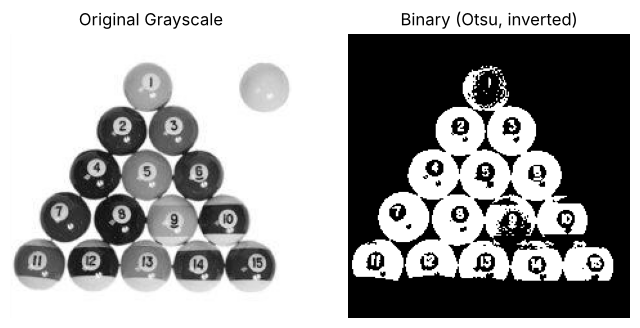

In [2]:
# Load, convert to grayscale, binarize (balls = white foreground)
img = cv2.imread(imgFile, 0)
img = img[12:-12, 12:-12]   # crop the thin black frame around the picture so it is not treated as foreground
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1), plt.imshow(img, 'gray'), plt.title('Original Grayscale'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(binary, 'gray'), plt.title('Binary (Otsu, inverted)'), plt.axis('off')
plt.show()

## **1. Erosion**
Erosion shrinks the white objects and removes small white details. A larger kernel gives a stronger shrink.

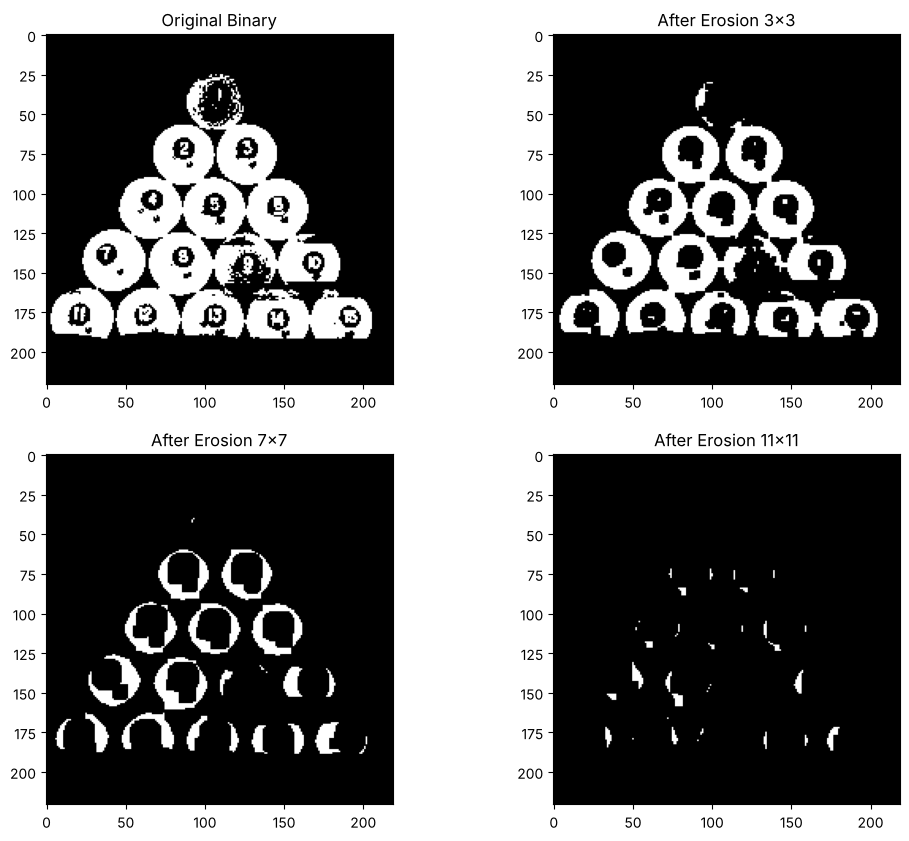

In [3]:
kernel3  = np.ones((3, 3), np.uint8)
kernel7  = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

eroded3  = cv2.erode(binary, kernel3,  iterations=1)
eroded7  = cv2.erode(binary, kernel7,  iterations=1)
eroded11 = cv2.erode(binary, kernel11, iterations=1)

plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1), plt.imshow(binary,   'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded3,  'gray'), plt.title('After Erosion 3x3')
plt.subplot(2, 2, 3), plt.imshow(eroded7,  'gray'), plt.title('After Erosion 7x7')
plt.subplot(2, 2, 4), plt.imshow(eroded11, 'gray'), plt.title('After Erosion 11x11')
plt.show()

**Observation:** The balls become smaller as the kernel grows. The internal number/dark-light patterns disappear first and with 11×11 the balls are heavily shrunk and the gaps between touching balls widen.

## **2. Dilation**
Dilation expands the white objects and fills small holes. A larger kernel gives stronger growth.

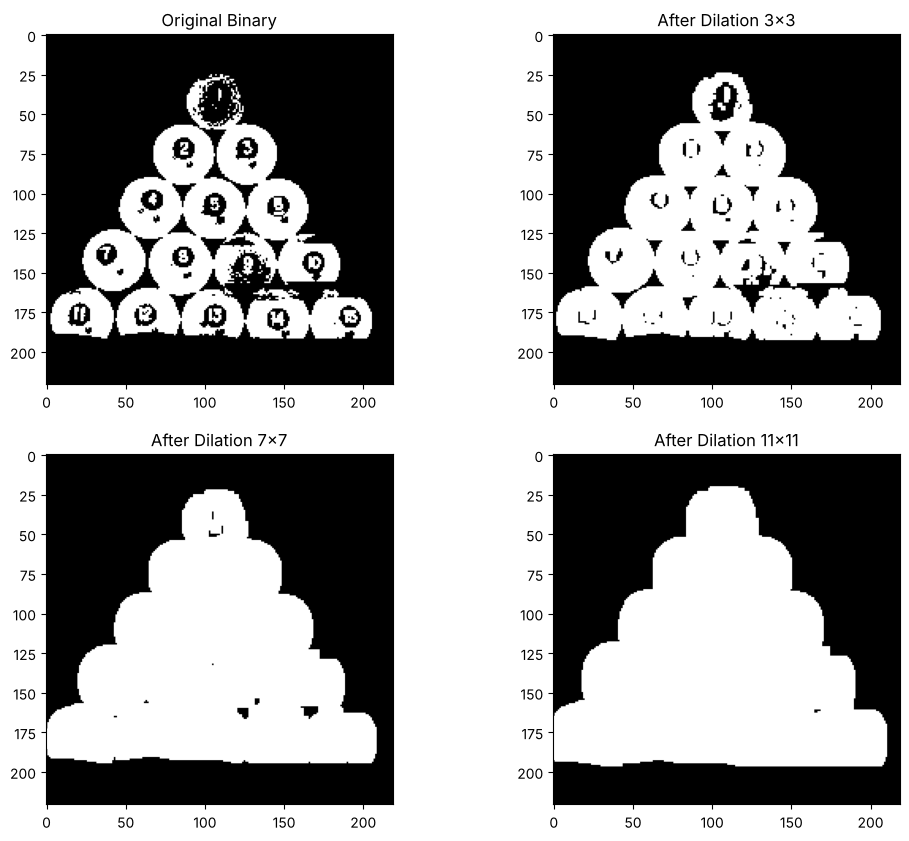

In [4]:
dilated3  = cv2.dilate(binary, kernel3,  iterations=1)
dilated7  = cv2.dilate(binary, kernel7,  iterations=1)
dilated11 = cv2.dilate(binary, kernel11, iterations=1)

plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1), plt.imshow(binary,    'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(dilated3,  'gray'), plt.title('After Dilation 3x3')
plt.subplot(2, 2, 3), plt.imshow(dilated7,  'gray'), plt.title('After Dilation 7x7')
plt.subplot(2, 2, 4), plt.imshow(dilated11, 'gray'), plt.title('After Dilation 11x11')
plt.show()

**Observation:** The balls grow and neighbouring balls start to merge into one connected blob. Small holes inside the balls are filled.

## **3. Opening** (erosion followed by dilation)
Opening removes small white specks/thin protrusions while roughly preserving the size of the main objects.

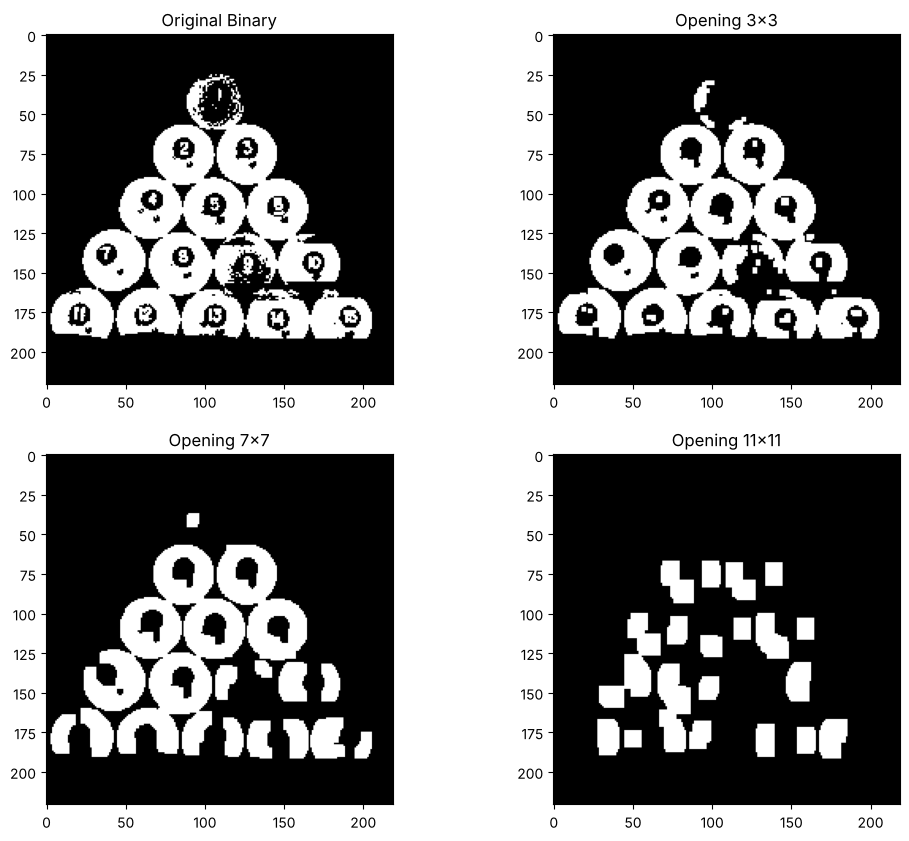

In [5]:
open3  = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel3)
open7  = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel7)
open11 = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel11)

plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(open3,  'gray'), plt.title('Opening 3x3')
plt.subplot(2, 2, 3), plt.imshow(open7,  'gray'), plt.title('Opening 7x7')
plt.subplot(2, 2, 4), plt.imshow(open11, 'gray'), plt.title('Opening 11x11')
plt.show()

**Observation:** Unlike erosion, the balls keep their original size. Small white noise and thin connections are removed, and the shapes are smoothed from the outside.

## **4. Closing** (dilation followed by erosion)
Closing fills small black holes and gaps inside the objects while roughly preserving their size.

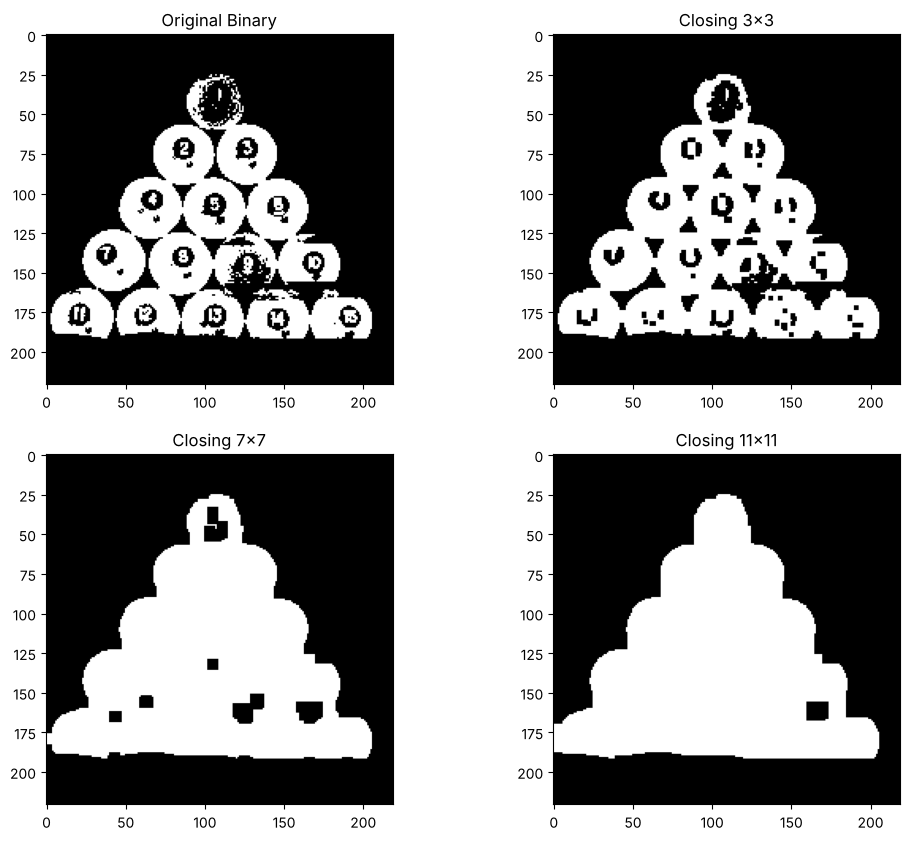

In [6]:
close3  = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel3)
close7  = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel7)
close11 = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel11)

plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1), plt.imshow(binary,  'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(close3,  'gray'), plt.title('Closing 3x3')
plt.subplot(2, 2, 3), plt.imshow(close7,  'gray'), plt.title('Closing 7x7')
plt.subplot(2, 2, 4), plt.imshow(close11, 'gray'), plt.title('Closing 11x11')
plt.show()

**Observation:** Black holes inside the balls (e.g. the numbers and dark patches) are filled, and small gaps between touching balls are bridged, while the overall ball size stays about the same.

## **Summary of all four operations (7x7 kernel)**

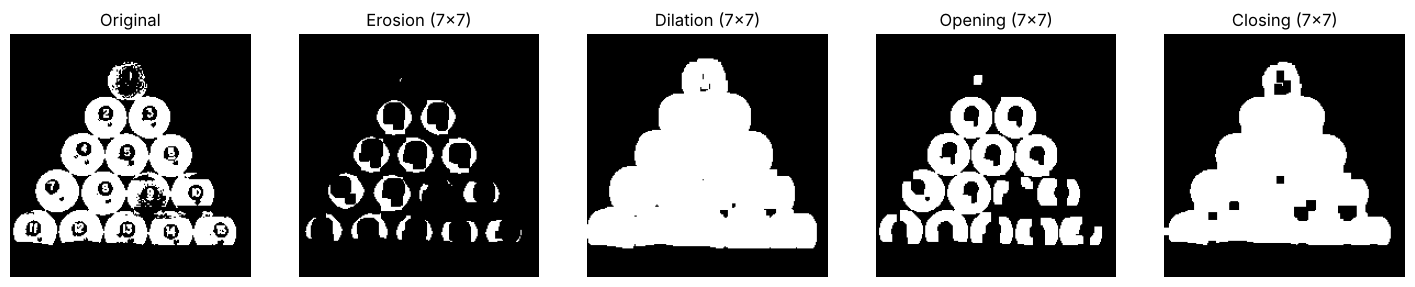

In [7]:
results = [binary, eroded7, dilated7, open7, close7]
titles  = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing']

plt.figure(figsize=(18, 4))
for i, (im, t) in enumerate(zip(results, titles)):
    plt.subplot(1, 5, i + 1)
    plt.imshow(im, 'gray'); plt.title(t + (' (7x7)' if i else '')); plt.axis('off')
plt.show()

# **Task 2: Experiment with structuring elements**

We apply erosion and dilation with three **shapes** (square, cross, ellipse) and three **sizes** (3×3, 5×5, 7×7) using `cv2.getStructuringElement`.

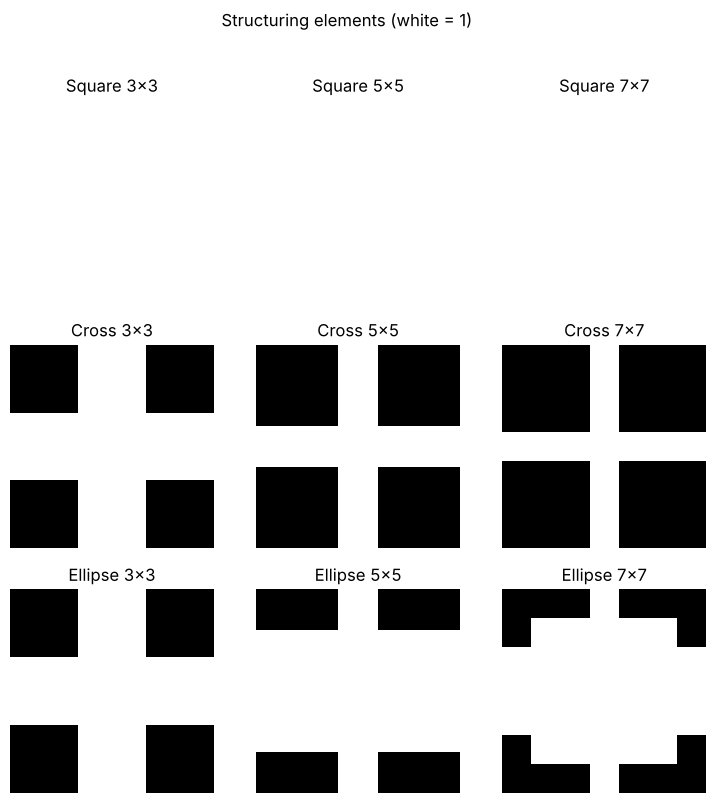

In [8]:
shapes = {'Square':  cv2.MORPH_RECT,
          'Cross':   cv2.MORPH_CROSS,
          'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]

# Show the structuring elements themselves
plt.figure(figsize=(9, 9))
k = 1
for name, shp in shapes.items():
    for s in sizes:
        plt.subplot(3, 3, k); k += 1
        plt.imshow(cv2.getStructuringElement(shp, (s, s)), 'gray', vmin=0, vmax=1)
        plt.title(f'{name} {s}x{s}'); plt.axis('off')
plt.suptitle('Structuring elements (white = 1)')
plt.show()

## **Erosion with different shapes and sizes**

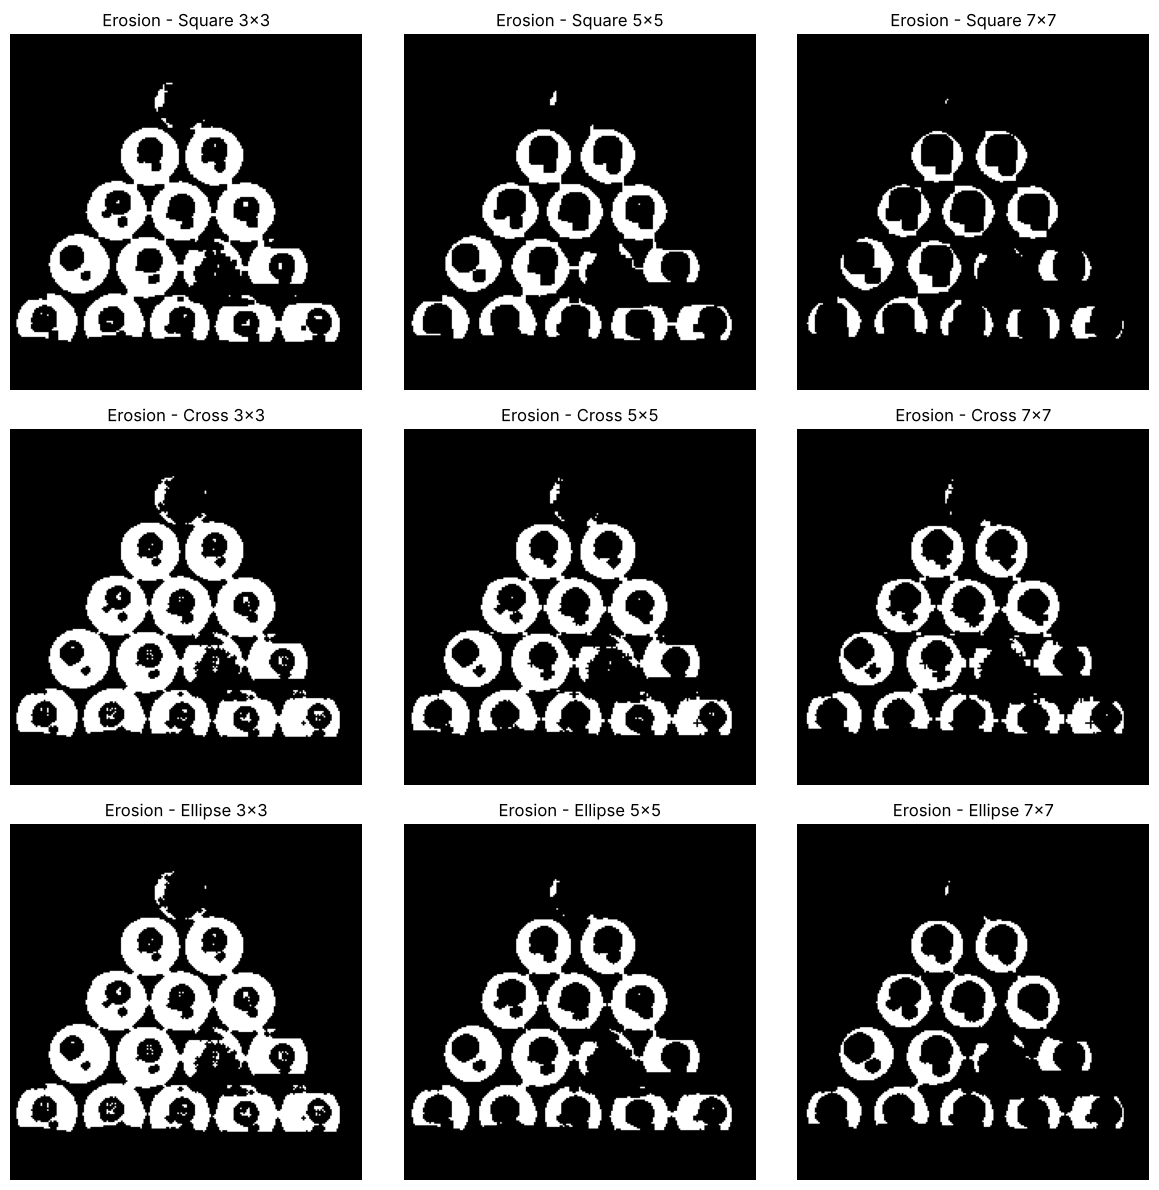

In [9]:
def grid(op, title):
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    out = {}
    for r, (name, shp) in enumerate(shapes.items()):
        for c, s in enumerate(sizes):
            se = cv2.getStructuringElement(shp, (s, s))
            res = op(binary, se)
            out[(name, s)] = res
            axes[r, c].imshow(res, 'gray')
            axes[r, c].set_title(f'{title} - {name} {s}x{s}')
            axes[r, c].axis('off')
    plt.tight_layout(); plt.show()
    return out

erode_res = grid(lambda im, se: cv2.erode(im, se), 'Erosion')

## **Dilation with different shapes and sizes**

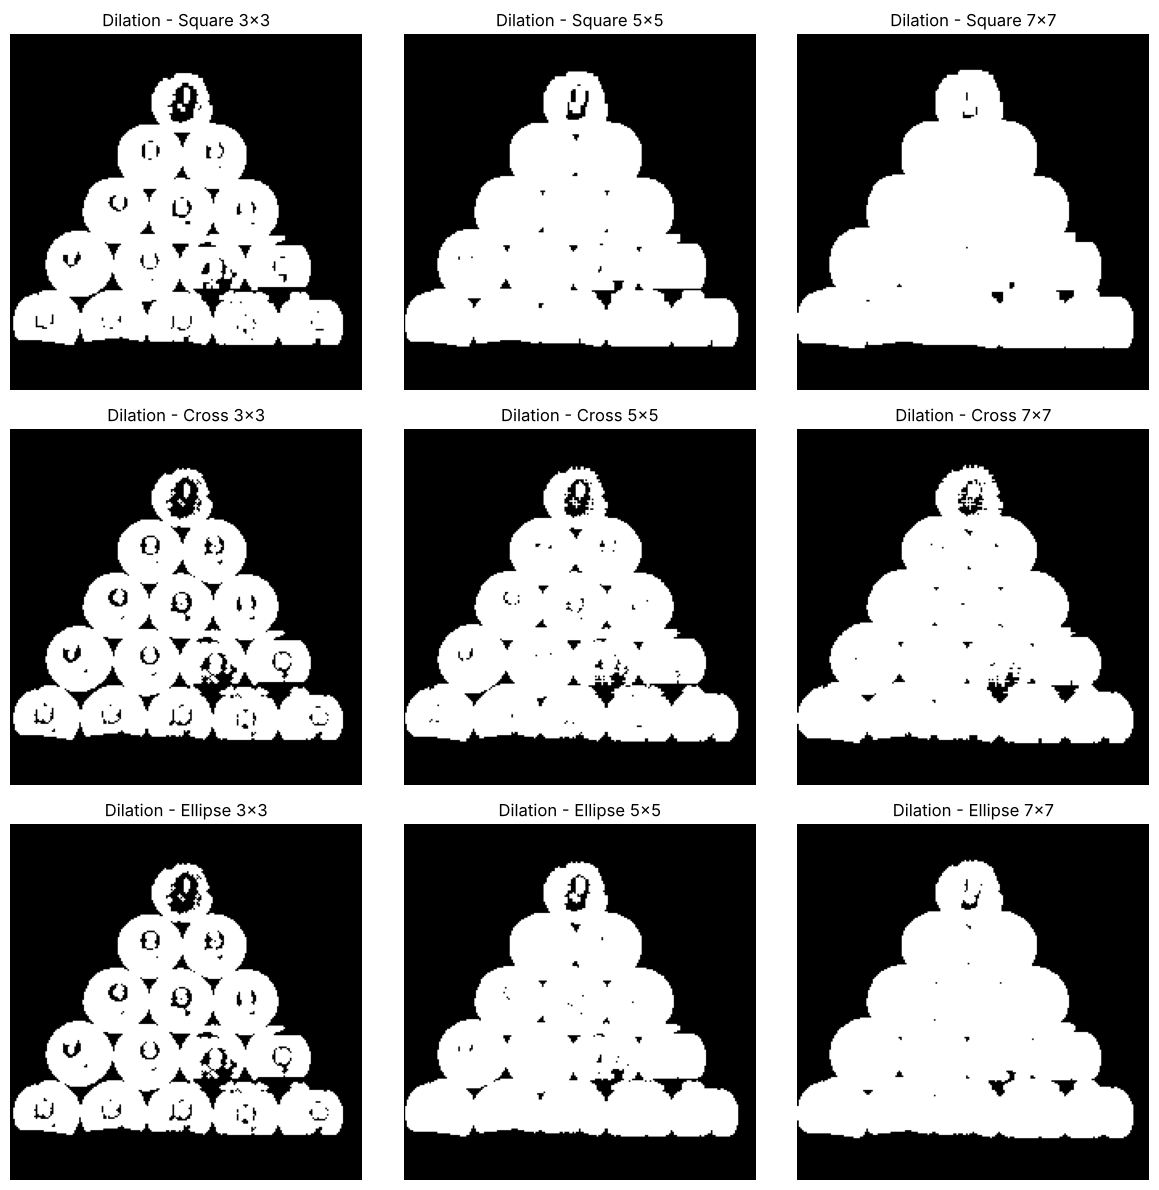

In [10]:
dilate_res = grid(lambda im, se: cv2.dilate(im, se), 'Dilation')

## **Quantitative comparison**
We count the white (foreground) pixels after each operation. Fewer pixels after erosion = stronger shrinking; more pixels after dilation = stronger growth.

In [11]:
import pandas as pd

orig = int((binary == 255).sum())
rows = []
for name in shapes:
    for s in sizes:
        e = int((erode_res[(name, s)]  == 255).sum())
        d = int((dilate_res[(name, s)] == 255).sum())
        rows.append({'Shape': name, 'Size': f'{s}x{s}',
                     'Eroded pixels': e, 'Erosion change %': round(100*(e-orig)/orig, 1),
                     'Dilated pixels': d, 'Dilation change %': round(100*(d-orig)/orig, 1)})

print('Original white pixels:', orig)
pd.DataFrame(rows)

Original white pixels: 13706


,Shape,Size,Eroded pixels,Erosion change %,Dilated pixels,Dilation change %
0,Square,3x3,9552,-30.3,17672,28.9
1,Square,5x5,6459,-52.9,19773,44.3
2,Square,7x7,3778,-72.4,20981,53.1
3,Cross,3x3,10582,-22.8,16762,22.3
4,Cross,5x5,8273,-39.6,18716,36.6
5,Cross,7x7,6304,-54.0,19905,45.2
6,Ellipse,3x3,10582,-22.8,16762,22.3
7,Ellipse,5x5,7476,-45.5,19257,40.5
8,Ellipse,7x7,5316,-61.2,20390,48.8


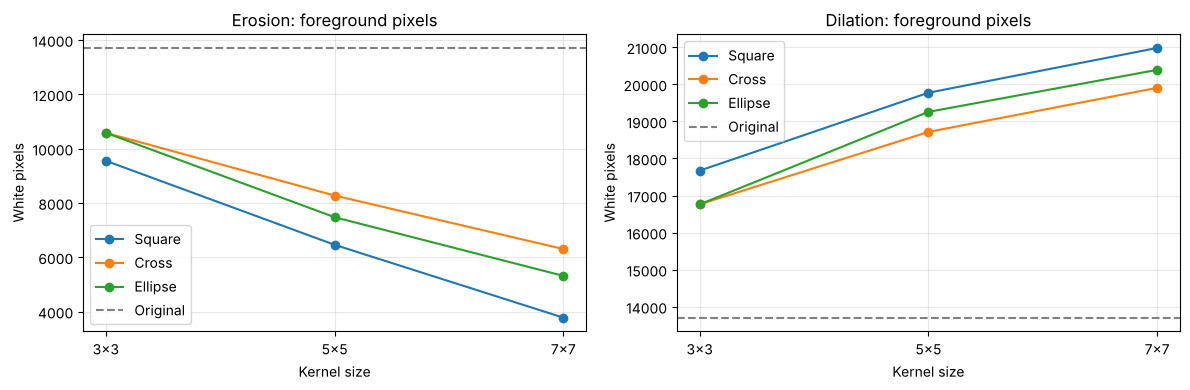

In [12]:
# Plot: foreground area versus kernel size for each shape
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df = pd.DataFrame(rows)
for name in shapes:
    sub = df[df.Shape == name]
    ax[0].plot(sub['Size'], sub['Eroded pixels'],  marker='o', label=name)
    ax[1].plot(sub['Size'], sub['Dilated pixels'], marker='o', label=name)
ax[0].axhline(orig, color='gray', ls='--', label='Original'); ax[1].axhline(orig, color='gray', ls='--', label='Original')
ax[0].set_title('Erosion: foreground pixels'); ax[1].set_title('Dilation: foreground pixels')
for a in ax: a.set_xlabel('Kernel size'); a.set_ylabel('White pixels'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## **Conclusions**

**Task 1**
- **Erosion** shrinks the balls and removes fine white details; **dilation** enlarges them and can merge neighbouring balls.
- **Opening** (erode → dilate) removes small white noise/thin links but keeps the balls at about their original size.
- **Closing** (dilate → erode) fills small black holes (numbers/dark patches) and small gaps but keeps the original size.

**Task 2**
- **Size:** the larger the kernel, the stronger the effect, since erosion removes more pixels and dilation adds more. The jump from 3×3 to 7×7 is large.
- **Shape:**
  - The **square** is the most aggressive; it affects all directions, including the diagonals, and produces squarish/blocky corners.
  - The **cross** is the mildest; it only acts along horizontal and vertical neighbours, so it changes diagonal edges least.
  - The **ellipse** (a disc-like element) is in between and best preserves the **round shape** of the balls, giving the most natural and isotropic result.
- For 3×3, the ellipse and cross kernels are identical in OpenCV, so their results match; differences appear from 5×5 upward.
- **Choice of kernel:** use the ellipse for round objects, the square for strong/fast removal, and the cross when you want minimal change to the objects.